# Forecasting 3 — Final Assignment

**Business context:** Sports retailer  
**Problem:** Predict weekly sales for each store to help with staff and stock planning.  
**Dataset:** `group_03_forecasting_3.csv`  

We follow the six CRISP-DM phases. The numbers and graphs below come from our data and Python code.

## Phase 1 — Business Understanding

Store managers need a sales forecast **before** they order stock and plan staff. Sunday evening is too late. For this assignment, we choose **Thursday before the target week** as the planning day. This is our assumption, not a confirmed company deadline.

For example, on Thursday in week 10, we predict sales for week 11. Week 10 is not finished yet. The latest complete sales week is week 9. This means we must use sales from **at least two weeks before the target week**.

We predict `sales_eur` for each store and target week. The forecast helps the planner prepare orders and staff plans. Our goal is at least 5% lower MAE than a simple baseline, without worse MAE for any store. This is our own test goal. We do not know actual ordering deadlines or business costs, so the company must check this timing before use.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA = Path('group_03_forecasting_3.csv')
if not DATA.exists():
    DATA = Path('/mnt/data/group_03_forecasting_3.csv')
raw = pd.read_csv(DATA)
print('Dataset shape:', raw.shape)
display(raw.head())

Dataset shape: (1065, 11)


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
0,S06,25-11-2024,NONE,0,11.2,10.5,6875,27.82,36396.09,1279.27,medium
1,S02,22-07-2024,none,0,21.6,6.5,9128,19.57,46580.82,2236.76,high
2,S08,04-03-2024,Discount,0,2.9,0.6,7825,38.01,38589.62,1048.21,medium
3,S02,09-03-2026,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
4,S06,02-12-2024,none,1,1.2,0.4,8382,40.54,37143.15,1487.54,medium


## Phase 2 — Data Understanding

We first look at the data to understand what we are trying to predict. Each row should show the sales of one store in one week. Our target is `sales_eur`.

We check how many stores and weeks are in the data. We also look for missing values, repeated store-weeks and differences in weekly sales. This helps us decide what we need to prepare before making a forecast.

We also check which columns we can use on Thursday, before the week we want to predict. We should not use information that is only known after that week has finished.


In [2]:
df = raw.copy()
df['week_start'] = pd.to_datetime(df['week_start'], dayfirst=True, errors='coerce')
print('Date range:', df.week_start.min(), 'to', df.week_start.max())
print('Stores:', df.store_id.nunique(), '| weeks:', df.week_start.nunique())
print('Missing by field:'); display(df.isna().sum().to_frame('missing'))
print('Duplicate store-week rows:', df.duplicated(['store_id','week_start']).sum())
print('Promo raw labels:'); display(df.promo_label.value_counts(dropna=False).to_frame('count'))
print('Sales distribution:'); display(df.sales_eur.describe().to_frame('sales_eur'))
print('Non-positive sales:', (df.sales_eur <= 0).sum())
print('Date parse failures:', df.week_start.isna().sum())
print('Five highest sales rows:')
display(df.nlargest(5,'sales_eur')[['store_id','week_start','sales_eur']])


Date range: 2024-01-01 00:00:00 to 2026-03-30 00:00:00
Stores: 9 | weeks: 118
Missing by field:


,missing
store_id,0
week_start,0
promo_label,71
holiday_week,0
temperature_actual,0
rain_mm_actual,0
footfall_actual,0
average_price_eur,18
sales_eur,0
returns_next_week_eur,0


Duplicate store-week rows: 3
Promo raw labels:


,count
promo_label,
none,470
discount,272
bundle,133
Discount,94
NaN,71
NONE,25


Sales distribution:


,sales_eur
count,1065.000000
mean,36832.336342
std,9816.546981
min,3791.040000
25%,32675.260000
50%,36118.020000
75%,42894.250000
max,169869.006000


Non-positive sales: 0
Date parse failures: 0
Five highest sales rows:


,store_id,week_start,sales_eur
808,S03,2024-10-21,169869.006
462,S09,2024-10-28,166970.214
628,S08,2025-02-24,142447.104
869,S01,2024-04-01,80249.730
459,S09,2025-11-03,51568.510


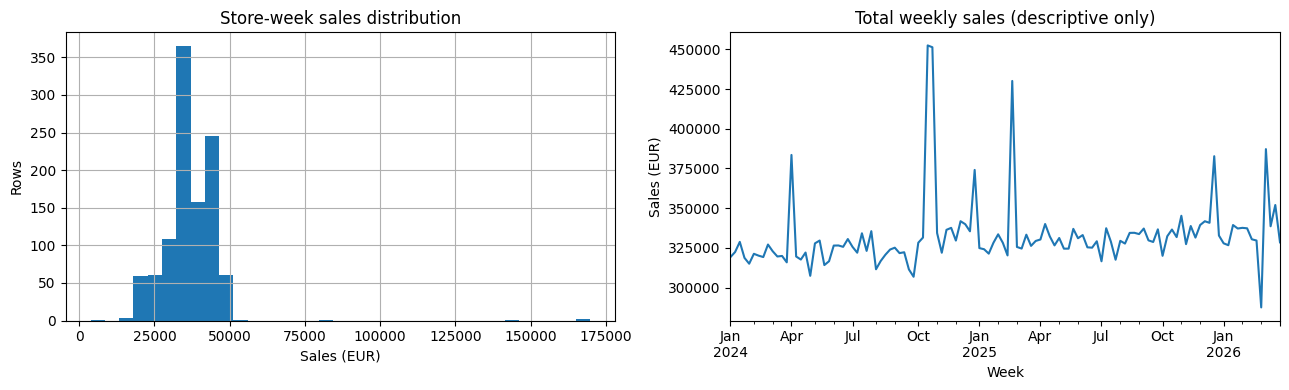

,count,mean,std,min,max
store_id,,,,,
S01,118,23082.44,5828.56,15809.59,80249.73
S02,119,45264.85,2155.83,39702.37,51059.85
S03,119,44741.58,11784.47,38473.75,169869.01
S04,118,35014.10,2198.38,28560.63,39736.14
S05,118,36673.81,2048.00,31185.51,41570.41
S06,118,34242.49,2185.74,29293.19,39723.21
S07,118,31319.16,2150.83,25027.86,36876.30
S08,118,36289.24,10058.92,30639.98,142447.10
S09,119,44658.54,12114.34,3791.04,166970.21


In [3]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
df.sales_eur.hist(ax=axes[0],bins=35)
axes[0].set(title='Store-week sales distribution',xlabel='Sales (EUR)',ylabel='Rows')
df.groupby('week_start').sales_eur.sum().sort_index().plot(ax=axes[1])
axes[1].set(title='Total weekly sales (descriptive only)',xlabel='Week',ylabel='Sales (EUR)')
plt.tight_layout(); plt.show()
display(df.groupby('store_id').sales_eur.agg(['count','mean','std','min','max']).round(2))

### What we found

The tables above help us see how the data is organised. We check whether a store has more than one row for the same week, because this can affect our forecast. We also check missing values and how much sales change between stores and weeks.

Some sales are much higher than others. This does not mean they are wrong. We keep the original sales values unless we have a clear reason to change them.

For our forecast, timing is important. On Thursday, the current week is not finished yet. This means we cannot use its final sales. In Phase 3, we use older completed weeks instead. We also leave out fields if we cannot be sure they are known when the forecast is made.


## Phase 3 — Data Preparation

We make three main choices and check the results.

**1. Repeated store-weeks.** We show the repeated rows before cleaning. For now, we use their average sales so each store-week appears once. We check the row count again. This is only a temporary rule: the data owner must tell us whether the rows are duplicates or separate sales records.

**2. Missing values and unusual sales.** We make promotion labels consistent, but do not use them in the model. We do not replace or cap high sales just because they look unusual. We compare model results with and without the highest observed sales row as a sensitivity check. We do **not** claim that this row is incorrect.

**3. Variables and timing.** We use the store, calendar and sales from completed weeks only. Our forecast is made on Thursday before the target week, so target-week `lag_1` is **not available**. We use `lag_2` and older weeks. We exclude actual weather, footfall, returns, after-week labels, and `average_price_eur` because we cannot prove it is known by Thursday. We check the new variables after making them.

We split by date, never randomly. No thresholds for changing sales are learned from the full dataset.


In [4]:
before = len(df)
conflicts = df.loc[df.duplicated(['store_id','week_start'],keep=False)].sort_values(['store_id','week_start'])
print('Duplicate-key source rows:'); display(conflicts)
df['promo_clean'] = df.promo_label.astype('string').str.strip().str.lower().fillna('unknown')
print('Promo categories after standardization:'); display(df.promo_clean.value_counts())
print('Missing prices before exclusion:', df.average_price_eur.isna().sum())
# Explicit provisional deduplication; non-target fields are not used as predictors.
panel = (df.groupby(['store_id','week_start'],as_index=False)
         .agg(sales_eur=('sales_eur','mean'))
         .sort_values(['store_id','week_start']).reset_index(drop=True))
assert not panel.duplicated(['store_id','week_start']).any()
print('Rows before / after:', before, len(panel))
print('Key duplicates after:',panel.duplicated(['store_id','week_start']).sum())
print('Dates per store:',panel.groupby('store_id').week_start.nunique().to_dict())

Duplicate-key source rows:


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
3,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
151,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,2984.26,high
220,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,1281.35,high
760,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,2950.96,high
848,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,654.19,high
993,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,1361.44,high


Promo categories after standardization:


promo_clean
none        495
discount    366
bundle      133
unknown      71
Name: count, dtype: Int64

Missing prices before exclusion: 18
Rows before / after: 1065 1062
Key duplicates after: 0
Dates per store: {'S01': 118, 'S02': 118, 'S03': 118, 'S04': 118, 'S05': 118, 'S06': 118, 'S07': 118, 'S08': 118, 'S09': 118}


In [5]:
panel['week_number'] = panel.week_start.dt.isocalendar().week.astype(int)
panel['month'] = panel.week_start.dt.month
panel['week_sin'] = np.sin(2*np.pi*panel.week_number/52.18)
panel['week_cos'] = np.cos(2*np.pi*panel.week_number/52.18)
g = panel.groupby('store_id',sort=False)['sales_eur']
for lag in [2,3,5,9]:
    panel[f'lag_{lag}'] = g.shift(lag)
panel['trailing_4_mean'] = panel.groupby('store_id',sort=False)['sales_eur'].transform(lambda x: x.shift(2).rolling(4).mean())
print('Before/after check: the first forecast uses week t-2 or older:')
display(panel.loc[panel.store_id == panel.store_id.iloc[0],['week_start','sales_eur','lag_2','lag_3','trailing_4_mean']].head(12))
model_data = panel.dropna(subset=['lag_2','lag_3','lag_5','lag_9','trailing_4_mean']).copy()
print('Rows available after creating older sales features:',len(model_data))
assert model_data[['lag_2','lag_3','lag_5','lag_9','trailing_4_mean']].notna().all().all()


Before/after check: the first forecast uses week t-2 or older:


,week_start,sales_eur,lag_2,lag_3,trailing_4_mean
0,2024-01-01,21393.60,NaN,NaN,NaN
1,2024-01-08,18429.52,NaN,NaN,NaN
2,2024-01-15,21566.87,21393.60,NaN,NaN
3,2024-01-22,20068.53,18429.52,21393.60,NaN
4,2024-01-29,19925.60,21566.87,18429.52,NaN
5,2024-02-05,20948.10,20068.53,21566.87,20364.6300
6,2024-02-12,18963.15,19925.60,20068.53,19997.6300
7,2024-02-19,21453.58,20948.10,19925.60,20627.2750
8,2024-02-26,22086.19,18963.15,20948.10,19976.3450
9,2024-03-04,23120.25,21453.58,18963.15,20322.6075


Rows available after creating older sales features: 981


## Phase 4 — Modelling

We predict sales on **Thursday before the target week**. We cannot use sales from the current unfinished week. The simple baseline uses sales from **two weeks before the target week** (`lag_2`). Our second method is a HistGradientBoosting model, which uses older sales, the store and the time of year.

We train on older dates, choose the model using later validation dates and test it on the final dates. This test represents a new Thursday forecast for each target week, using only information available by that Thursday. It is **not** a fixed 12-week forecast made all at once.

We compare the models using MAE, which is the average error in euros. We also check whether predictions are too high or too low.


In [6]:
dates = np.array(sorted(model_data.week_start.unique()))
cut1, cut2 = dates[int(len(dates)*0.65)], dates[int(len(dates)*0.80)]
train = model_data[model_data.week_start < cut1].copy()
val = model_data[(model_data.week_start >= cut1)&(model_data.week_start < cut2)].copy()
test = model_data[model_data.week_start >= cut2].copy()
print('Cutoffs:',pd.Timestamp(cut1).date(),pd.Timestamp(cut2).date())
for label,part in [('train',train),('validation',val),('test',test)]:
    print(label,len(part),part.week_start.min().date(),part.week_start.max().date())
assert train.week_start.max() < val.week_start.min() < test.week_start.min()
base_features = ['lag_2','lag_3','lag_5','lag_9','trailing_4_mean','month','week_sin','week_cos']
store_columns = ['store_'+s for s in sorted(model_data.store_id.unique())]
def features(frame):
    x = frame[base_features].copy()
    for s,c in zip(sorted(model_data.store_id.unique()),store_columns):
        x[c] = (frame.store_id == s).astype(int)
    return x

def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'MAE_EUR':mean_absolute_error(y,p),
            'RMSE_EUR':np.sqrt(mean_squared_error(y,p)),
            'WAPE_pct':100*np.abs(y-p).sum()/np.abs(y).sum(),
            'Bias_EUR':np.mean(p-y)}

results=[]
for depth in [2,3,4]:
    candidate=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=2**depth,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
    candidate.fit(features(train),train.sales_eur)
    pred=candidate.predict(features(val))
    results.append({'max_leaf_nodes':2**depth,**metrics(val.sales_eur,pred)})
validation_results=pd.DataFrame(results).sort_values('MAE_EUR')
print('Candidate validation results:');display(validation_results.round(2))
print('Naive validation:');display(pd.DataFrame([metrics(val.sales_eur,val.lag_2)]).round(2))
best_leaves=int(validation_results.iloc[0].max_leaf_nodes)
print('Chosen leaves using validation only:',best_leaves)

Cutoffs: 2025-07-07 2025-11-03
train 630 2024-03-04 2025-06-30
validation 153 2025-07-07 2025-10-27
test 198 2025-11-03 2026-03-30


Candidate validation results:


,max_leaf_nodes,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
2,16,2562.41,3808.90,6.98,520.71
1,8,2595.43,3849.12,7.07,496.52
0,4,2777.86,3987.50,7.57,692.65


Naive validation:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
0,2151.15,2659.41,5.86,-91.78


Chosen leaves using validation only: 16


## Phase 5 — Evaluation

We compare the baseline and model on the final test weeks. We check MAE, WAPE, average over- or underprediction, and results for each store.

A forecast that is **too low** can mean too little stock and too few staff, leading to missed sales or longer waiting times. A forecast that is **too high** can mean extra stock or too many staff hours. We do not have actual cost figures, so these are possible effects, not measured losses.

We also test what happens if we leave out the single highest original sales row **from model training only**. The test period stays unchanged. This is a check of how much that unusual value matters, not proof that it is wrong.


Final held-out test results:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR,MAE_vs_naive_pct
Naive two weeks ago,2749.18,5159.28,7.41,-61.31,0.00
Candidate model,2468.58,4136.58,6.65,-228.42,-10.21


Store-level held-out results:


,store_id,naive_MAE,candidate_MAE,candidate_WAPE_pct,candidate_bias_EUR,MAE_change_pct
0,S01,1674.10,1702.49,6.99,-903.12,1.70
1,S02,2596.70,3015.70,6.51,-1600.19,16.14
2,S03,1790.32,2578.69,5.69,-997.72,44.03
3,S04,2743.57,1960.80,5.59,157.83,-28.53
4,S05,2165.15,2323.85,6.21,313.43,7.33
5,S06,2047.84,2297.56,6.51,-282.29,12.19
6,S07,2537.07,1723.67,5.64,986.52,-32.06
7,S08,2755.25,2080.24,5.80,582.63,-24.50
8,S09,6432.58,4534.23,10.33,-312.88,-29.51


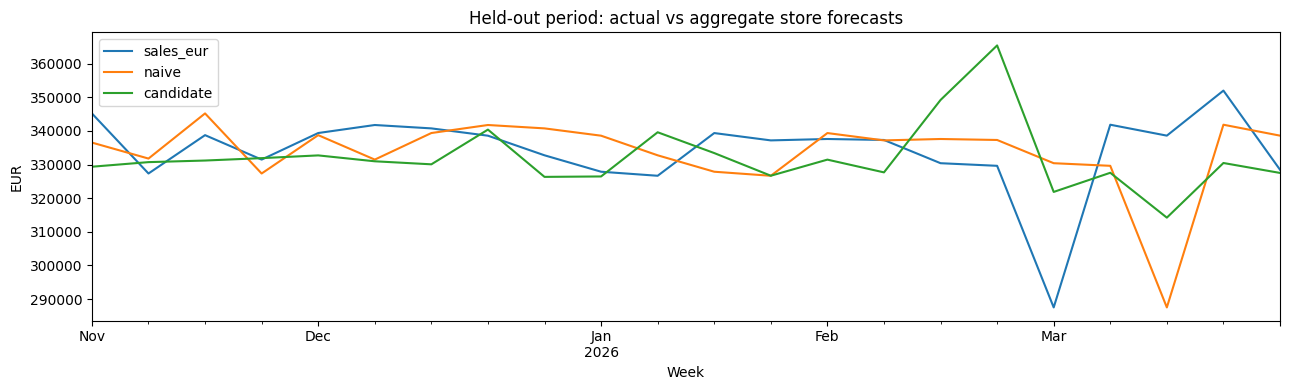

In [7]:
trainval=pd.concat([train,val],ignore_index=True)
final_model=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
final_model.fit(features(trainval),trainval.sales_eur)
eval_df=test[['store_id','week_start','sales_eur']].copy()
eval_df['naive']=test.lag_2.to_numpy()
eval_df['candidate']=final_model.predict(features(test))
comparison=pd.DataFrame({'Naive two weeks ago':metrics(eval_df.sales_eur,eval_df.naive),
                         'Candidate model':metrics(eval_df.sales_eur,eval_df.candidate)}).T
comparison['MAE_vs_naive_pct']=100*(comparison.MAE_EUR/comparison.loc['Naive two weeks ago','MAE_EUR']-1)
print('Final held-out test results:');display(comparison.round(2))
rows=[]
for store,grp in eval_df.groupby('store_id'):
    a=metrics(grp.sales_eur,grp.naive);b=metrics(grp.sales_eur,grp.candidate)
    rows.append({'store_id':store,'naive_MAE':a['MAE_EUR'],'candidate_MAE':b['MAE_EUR'],
                 'candidate_WAPE_pct':b['WAPE_pct'],'candidate_bias_EUR':b['Bias_EUR'],
                 'MAE_change_pct':100*(b['MAE_EUR']/a['MAE_EUR']-1)})
store_results=pd.DataFrame(rows)
print('Store-level held-out results:');display(store_results.round(2))
fig,ax=plt.subplots(figsize=(13,4))
weekly=eval_df.groupby('week_start')[['sales_eur','naive','candidate']].sum()
weekly.plot(ax=ax);ax.set(title='Held-out period: actual vs aggregate store forecasts',ylabel='EUR',xlabel='Week');plt.tight_layout();plt.show()

In [8]:
naive_mae=comparison.loc['Naive two weeks ago','MAE_EUR']
model_mae=comparison.loc['Candidate model','MAE_EUR']
improvement=100*(naive_mae-model_mae)/naive_mae
store_worse=(store_results.MAE_change_pct>0).sum()
print(f'Test MAE improvement versus naive: {improvement:.1f}% (positive means improvement).')
print(f'Stores with worse candidate MAE: {store_worse} of {len(store_results)}.')
if improvement >= 5 and store_worse == 0:
    print('Decision: limited, human-reviewed pilot is defensible; no autonomous deployment.')
elif improvement > 0:
    print('Decision: revise or run a closely monitored shadow pilot; the provisional 5% / store criteria are not fully satisfied.')
else:
    print('Decision: retain naive baseline; revise candidate before any operational pilot.')
print('Interpretation: MAE is the average absolute store-week forecast error in EUR; bias identifies average over/underprediction.')

Test MAE improvement versus naive: 10.2% (positive means improvement).
Stores with worse candidate MAE: 5 of 9.
Decision: revise or run a closely monitored shadow pilot; the provisional 5% / store criteria are not fully satisfied.
Interpretation: MAE is the average absolute store-week forecast error in EUR; bias identifies average over/underprediction.


### Remaining limits

The company still needs to confirm that Thursday is early enough to plan stock orders and staff schedules. We have tested one final time period. Testing several different time periods would help us understand whether the results stay similar over time.

We also need to check whether planned promotions are really known before the forecast is made. If they are not, we should not use them as input.


## Phase 6 — Deployment

We would make each forecast on **Thursday**, before the target week starts. This is a suggested planning day; the retailer must confirm when stock orders and staff schedules are actually decided. The forecast uses the latest **fully completed** week, not the unfinished current week.

The planner checks the forecast against the simple baseline. Store managers can change it if they know about a local event, missing delivery or another issue. They must write down why.

During a small test, we would save each Thursday forecast before the week starts. After the week, we compare it with real sales. We check average error, underprediction and results for every store. We also ask managers whether the forecast arrived early enough and helped them plan.

**Before a wider rollout**, we want at least four completed pilot weeks, lower MAE than the baseline by our chosen 5% goal, no store with consistently worse MAE, no repeated serious underforecasting, and confirmation from managers that the timing and data are useful. These are proposed checks, not company rules. If data is missing or the four-week MAE becomes over 10% worse than the baseline, we pause and review the model.


## Final checks

We used the supplied Group 03 CSV. Our main decision is to test carefully, not automatically use the model for orders or staffing. We do not know whether the highest sales amounts are mistakes. We do not use the current unfinished week's sales when making the Thursday forecast. We should confirm the planning deadline and check repeated rows with the data owner before real use.
